# STAGE 2 – TASK 3: REGRESSION
## Dự đoán giá sản phẩm

**Dataset:** `cleaned_data.csv`

### Mục tiêu
Xây dựng và so sánh 2 mô hình:
1. `LinearRegression()`
2. `DecisionTreeRegressor()`

### Evaluation Metrics
- MSE
- RMSE
- R² Score

### Visualization
- Actual vs Predicted
- Residual Plot

### Output
- `regression_model.pkl`
- `regression_scaler.pkl`
- `linear_regression_model.pkl`
- `regression_results.csv`
- `regression_features.pkl`


## 1. Import thư viện

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 2. Đọc dataset

Đầu vào là dataset đã được Cleaning ở Stage 1.

In [3]:
# Đọc file cleaned_data.csv
df = pd.read_csv(r"F:\DUONG\DATA & AI\STAGE1\DUONG_SQLite_Cleaning\cleaned_data.csv")

print("Kích thước dataset:", df.shape)
print("\nCác cột:")
print(df.columns.tolist())

display(df.head())


Kích thước dataset: (689, 21)

Các cột:
['product_name', 'price', 'tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'release_year', 'manufacturer', 'model_name', 'rating', 'num_reviews', 'specifications', 'source', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity', 'data_date']


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,"18,390,000.0000",Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,"2,026.0000",...,Unknown,4.3000,7.0000,Unknown,dienmayxanh,7370,453,3.2000,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,"19,990,000.0000",Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,"2,025.0000",...,Unknown,4.3000,7.0000,Unknown,dienmayxanh,960,373,4.3000,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,"7,690,000.0000",Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,"2,025.0000",...,Unknown,4.3000,7.0000,Unknown,dienmayxanh,5490,492,4.5000,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,"7,690,000.0000",Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,"2,022.0000",...,Unknown,4.3000,7.0000,Unknown,dienmayxanh,5291,292,4.7000,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,"18,490,000.0000",Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,"2,026.0000",...,Unknown,4.3000,7.0000,Unknown,dienmayxanh,5834,38,3.2000,124,2026-01-05


## 3. Kiểm tra biến mục tiêu

Chọn `price` làm biến mục tiêu vì đây là biến số liên tục và phù hợp với bài toán dự đoán giá sản phẩm.

**Lưu ý:** Không đưa `price` vào tập đặc trưng X để tránh Data Leakage.

In [4]:
print("Thông tin biến price:")
display(df["price"].describe())

print("\nSố lượng missing của price:", df["price"].isna().sum())


Thông tin biến price:


count             689.0000
mean       20,308,922.1146
std       130,846,339.6482
min                 6.9100
25%                24.1400
50%             1,299.9900
75%        18,990,000.0000
max     3,299,000,000.0000
Name: price, dtype: float64


Số lượng missing của price: 0


## 4. Chọn Features và Target

### Target:
`price`

### Features:
- screen_size
- ram
- rom
- release_year
- rating
- num_reviews
- monthly_views
- monthly_orders
- customer_rating
- stock_quantity

Các cột text như tên sản phẩm, mô tả, hệ điều hành... không đưa trực tiếp vào hai mô hình Regression này.

In [5]:
features = [
    "screen_size",
    "ram",
    "rom",
    "release_year",
    "rating",
    "num_reviews",
    "monthly_views",
    "monthly_orders",
    "customer_rating",
    "stock_quantity"
]

target = "price"

# Chuyển các cột chứa đơn vị sang số
# Ví dụ: "65 inch" -> 65, "4 GB" -> 4
for col in ["screen_size", "ram", "rom"]:
    df[col] = (
        df[col]
        .astype(str)
        .str.extract(r"(\d+(?:\.\d+)?)", expand=False)
        .astype(float)
    )

# X và y
X = df[features].copy()
y = df[target].copy()

# Xử lý missing ở feature bằng median
X = X.fillna(X.median())

# Loại các dòng thiếu target
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

print("Features sử dụng:")
print(features)
print("\nKích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("\nMissing trong X:", X.isna().sum().sum())
print("Missing trong y:", y.isna().sum())


Features sử dụng:
['screen_size', 'ram', 'rom', 'release_year', 'rating', 'num_reviews', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity']

Kích thước X: (689, 10)
Kích thước y: (689,)

Missing trong X: 0
Missing trong y: 0


## 5. Kiểm tra Data Leakage

`price` phải là target và **không được xuất hiện trong X**.

In [8]:
print("price có nằm trong X không?", "price" in X.columns)

assert "price" not in X.columns, "ERROR: Data Leakage – price đang nằm trong X!"

print("=> Không phát hiện Data Leakage từ biến target.")


price có nằm trong X không? False
=> Không phát hiện Data Leakage từ biến target.


## 6. Chia Training Set và Test Set

Sử dụng `train_test_split`:
- 80% Training
- 20% Testing
- `random_state=42` để kết quả có thể tái lập.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)


Training set: (551, 10)
Test set: (138, 10)


## 7. Feature Scaling

Sử dụng `StandardScaler`.

**Quan trọng:** scaler chỉ được `fit` trên Training set, sau đó dùng để transform Test set. Cách này tránh data leakage.

In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Đã hoàn thành StandardScaler.")


Đã hoàn thành StandardScaler.


## 8. Model 1 – Linear Regression

In [11]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_scaled)

print("Linear Regression đã được huấn luyện.")


Linear Regression đã được huấn luyện.


## 9. Model 2 – Decision Tree Regressor

In [12]:
tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_model.fit(X_train_scaled, y_train)

y_pred_tree = tree_model.predict(X_test_scaled)

print("Decision Tree Regressor đã được huấn luyện.")


Decision Tree Regressor đã được huấn luyện.


## 10. Đánh giá mô hình

### Metrics
- **MSE:** càng thấp càng tốt.
- **RMSE:** càng thấp càng tốt.
- **R²:** nhìn chung càng cao càng tốt.

In [13]:
def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mse, rmse, r2

linear_mse, linear_rmse, linear_r2 = calculate_metrics(
    y_test, y_pred_linear
)

tree_mse, tree_rmse, tree_r2 = calculate_metrics(
    y_test, y_pred_tree
)

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regressor"
    ],
    "MSE": [
        linear_mse,
        tree_mse
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse
    ],
    "R2 Score": [
        linear_r2,
        tree_r2
    ]
})

display(results)


,Model,MSE,RMSE,R2 Score
0,Linear Regression,"3,283,544,461,182,243.0000","57,302,220.3861",0.1618
1,Decision Tree Regressor,"1,616,155,762,630,993.5000","40,201,439.8079",0.5874


## 11. So sánh hai mô hình

Model tốt hơn được xác định dựa trên:
- MSE thấp hơn
- RMSE thấp hơn
- R² cao hơn

In [20]:
print("=== KẾT QUẢ SO SÁNH ===")

print(results.to_string(
    index=False,
    formatters={
        "MSE |": lambda x: f"{x:,.2f} |",
        "RMSE |": lambda x: f"{x:,.2f} |",
        "R2 Score": lambda x: f"{x:.4f} "
    }
))

# Chọn model dựa chủ yếu vào R²,
# đồng thời kiểm tra MSE và RMSE.
if (
    tree_r2 > linear_r2
    and tree_mse < linear_mse
    and tree_rmse < linear_rmse
):
    best_model = tree_model
    best_model_name = "Decision Tree Regressor"
else:
    best_model = linear_model
    best_model_name = "Linear Regression"

print("\nModel được lựa chọn:", best_model_name)


=== KẾT QUẢ SO SÁNH ===
                  Model                        MSE            RMSE R2 Score
      Linear Regression 3,283,544,461,182,243.0000 57,302,220.3861  0.1618 
Decision Tree Regressor 1,616,155,762,630,993.5000 40,201,439.8079  0.5874 

Model được lựa chọn: Decision Tree Regressor


## 12. Actual vs Predicted – Linear Regression

Biểu đồ so sánh giá thực tế với giá được dự đoán.

Đường chéo thể hiện trường hợp dự đoán hoàn hảo: Actual = Predicted.

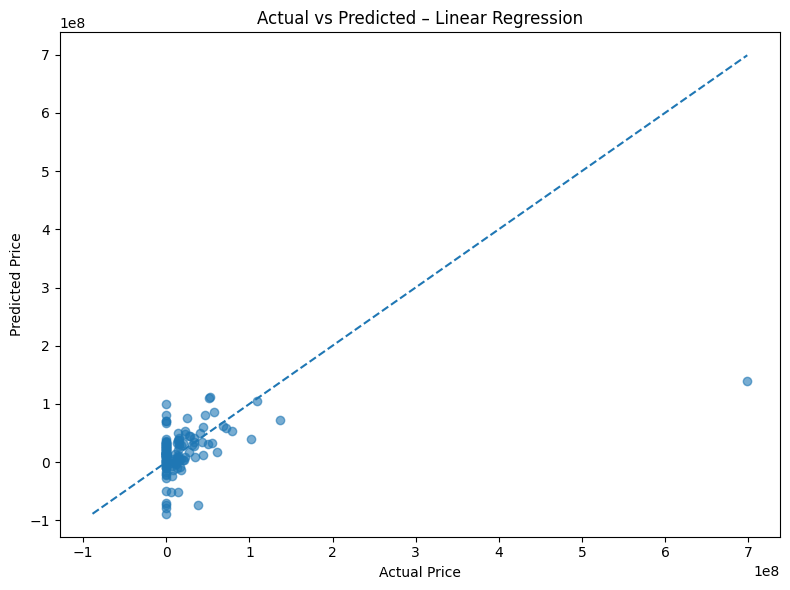

In [22]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.6
)

min_value = min(y_test.min(), y_pred_linear.min())
max_value = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted – Linear Regression")
plt.tight_layout()
plt.show()


## 13. Actual vs Predicted – Decision Tree Regressor

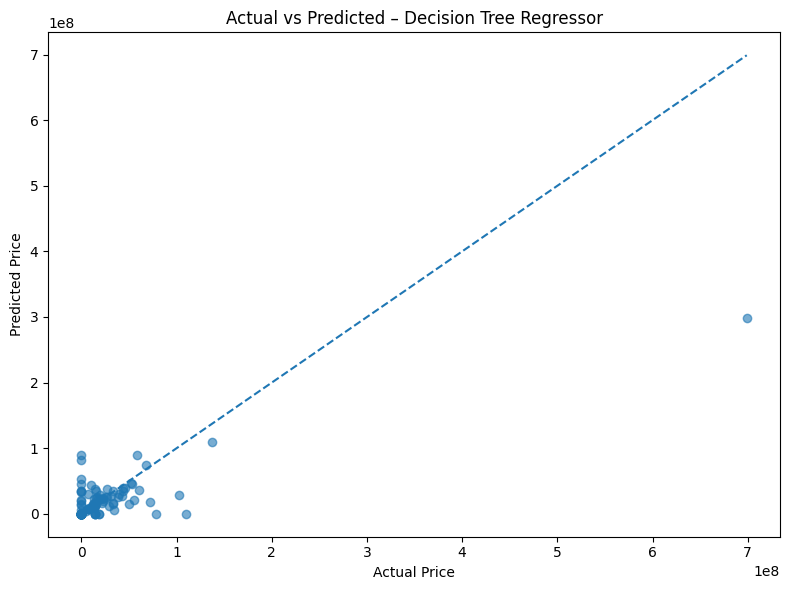

In [24]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    y_pred_tree,
    alpha=0.6
)

min_value = min(y_test.min(), y_pred_tree.min())
max_value = max(y_test.max(), y_pred_tree.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted – Decision Tree Regressor")
plt.tight_layout()
plt.show()


## 14. Residual Plot – Linear Regression

Residual = Actual − Predicted.

Nếu mô hình tốt, residual nên phân bố tương đối ngẫu nhiên quanh đường 0.

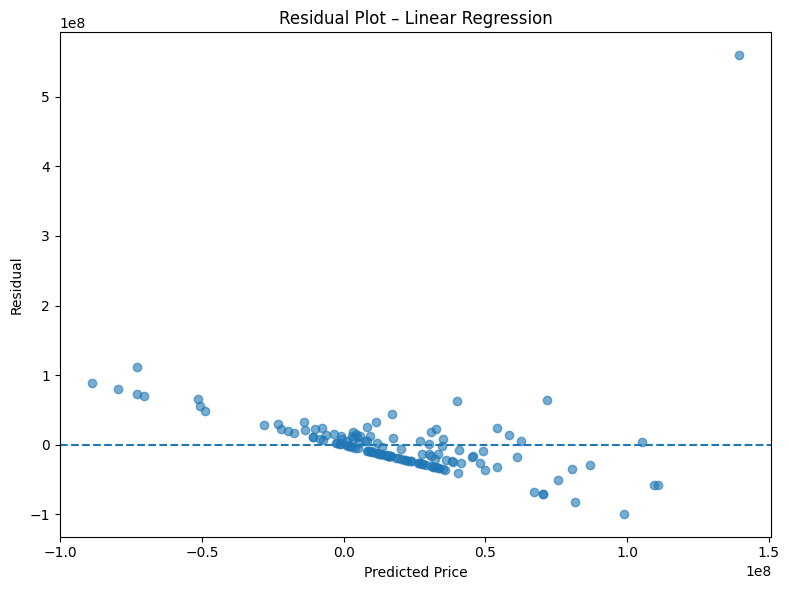

In [25]:
linear_residuals = y_test - y_pred_linear

plt.figure(figsize=(8, 6))
plt.scatter(
    y_pred_linear,
    linear_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot – Linear Regression")
plt.tight_layout()
plt.show()


## 15. Residual Plot – Decision Tree Regressor

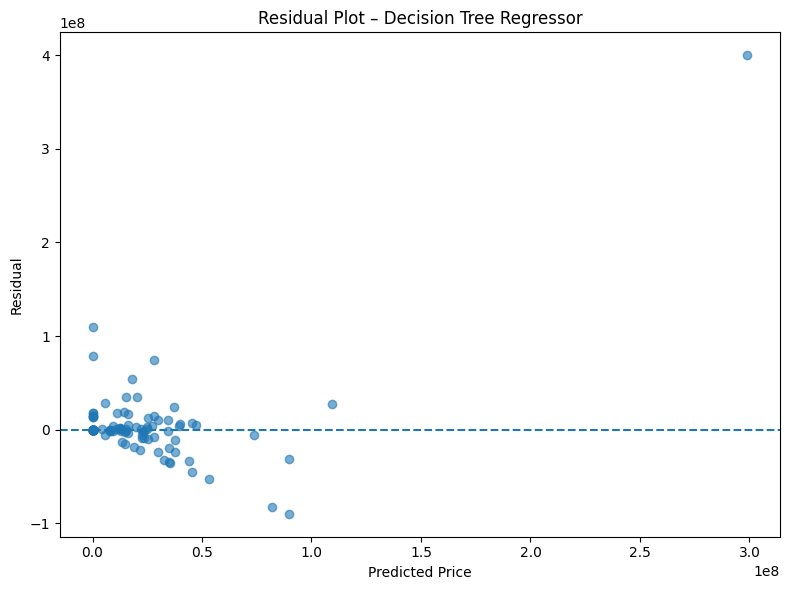

In [26]:
tree_residuals = y_test - y_pred_tree

plt.figure(figsize=(8, 6))
plt.scatter(
    y_pred_tree,
    tree_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot – Decision Tree Regressor")
plt.tight_layout()
plt.show()


## 16. Kết luận Regression

Dựa trên MSE, RMSE và R², chọn mô hình có:
- MSE thấp hơn
- RMSE thấp hơn
- R² cao hơn

Kết quả của notebook sẽ được dùng để lựa chọn model cuối cùng cho UI.

In [27]:
print("========== KẾT LUẬN ==========")
print(f"Linear Regression:")
print(f"  MSE  = {linear_mse:,.2f}")
print(f"  RMSE = {linear_rmse:,.2f}")
print(f"  R²   = {linear_r2:.4f}")

print(f"\nDecision Tree Regressor:")
print(f"  MSE  = {tree_mse:,.2f}")
print(f"  RMSE = {tree_rmse:,.2f}")
print(f"  R²   = {tree_r2:.4f}")

print(f"\n=> Model được chọn: {best_model_name}")


========== KẾT LUẬN ==========
Linear Regression:
  MSE  = 3,283,544,461,182,243.00
  RMSE = 57,302,220.39
  R²   = 0.1618

Decision Tree Regressor:
  MSE  = 1,616,155,762,630,993.50
  RMSE = 40,201,439.81
  R²   = 0.5874

=> Model được chọn: Decision Tree Regressor


## 17. Lưu các file để bàn giao cho Tài – UI

Các file quan trọng:
- `regression_model.pkl`: model Regression tốt nhất.
- `regression_scaler.pkl`: scaler dùng trong preprocessing.
- `regression_features.pkl`: thứ tự các feature đầu vào.
- `linear_regression_model.pkl`: model Linear Regression để lưu lại kết quả so sánh.
- `regression_results.csv`: bảng metrics.

In [28]:
# Lưu model tốt nhất
with open("regression_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

# Lưu scaler
with open("regression_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# Lưu Linear Regression để tham khảo
with open("linear_regression_model.pkl", "wb") as f:
    pickle.dump(linear_model, f)

# Lưu thứ tự feature để UI nhập đúng thứ tự
with open("regression_features.pkl", "wb") as f:
    pickle.dump(features, f)

# Lưu bảng kết quả
results.to_csv("regression_results.csv", index=False)

print("Đã lưu:")
print("- regression_model.pkl")
print("- regression_scaler.pkl")
print("- linear_regression_model.pkl")
print("- regression_features.pkl")
print("- regression_results.csv")


Đã lưu:
- regression_model.pkl
- regression_scaler.pkl
- linear_regression_model.pkl
- regression_features.pkl
- regression_results.csv


## 18. Báo cáo nhận xét

Nhóm xây dựng hai mô hình Linear Regression và Decision Tree Regressor để dự đoán giá sản phẩm. Hai mô hình được đánh giá trên tập Test bằng MSE, RMSE và R² Score. Mô hình được lựa chọn là mô hình có MSE và RMSE thấp hơn, đồng thời R² cao hơn.

Vì Decision Tree có kết quả tốt hơn, nhóm lựa chọn Decision Tree Regressor làm mô hình cuối cùng để tích hợp vào giao diện Web UI.

Ngoài ra, biểu đồ Actual vs Predicted và Residual Plot được sử dụng để quan sát sai số dự đoán và mức độ phù hợp của mô hình.
